# RTM of real marine data: Viking Graben line 12 with DENISE

Real 2D streamer data (Mobil, North Sea): 1001 shots x 120 channels, 25 m shot and receiver spacing,
offsets 262-3237 m (receivers trail the source), 6 s at 4 ms.

Workflow
1. Load SEG-Y, check geometry
2. Pre-process: kill bad traces, band-pass, mute direct wave, 3D->2D correction
3. Pick the sea floor
4. Velocity analysis (semblance, guided picking) -> Dix -> depth velocity model
5. Brute NMO stack (time) for QC
6. Write the data in DENISE format (time shift + resampling) and run acoustic RTM
7. Image post-processing (Laplacian, mute, gain) and QC

What real data does that synthetic data did not: free-surface multiples, a non-Ricker source,
3D spreading, noise, and an unknown velocity. Expect false reflectors from multiples below the
first water-bottom multiple (about 2x the sea-floor time). That is normal without SRME.

In [1]:
# Setup
import os, sys, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import segyio
from scipy.signal import butter, sosfiltfilt, hilbert
from scipy.ndimage import gaussian_filter, gaussian_filter1d, median_filter, uniform_filter1d
from scipy.interpolate import CubicSpline

# >>> EDIT paths (MacBook defaults). Keep WORKDIR short: DENISE limits path lengths.
SEGY        = os.environ.get("VK_SEGY", os.path.expanduser("~/viking/seismic.segy"))
DENISE_ROOT = os.environ.get("DENISE", os.path.expanduser("~/C++/DENISE-Black-Edition"))
WORKDIR     = os.environ.get("VK_WORK", os.path.expanduser("~/vk_rtm"))
MPIRUN      = os.environ.get("MPIRUN", "/opt/homebrew/bin/mpirun")   # Intel Mac: /usr/local/bin/mpirun
NPROCX, NPROCY = int(os.environ.get("VK_NPROCX", 4)), 1             # cores = NPROCX * NPROCY

# >>> EDIT imaging window and cost. Start small; widen once it works.
X_MIN = float(os.environ.get("VK_XMIN", 10000.0))   # migrate shots whose source x is in [X_MIN, X_MAX] [m]
X_MAX = float(os.environ.get("VK_XMAX", 18000.0))
SHOT_STEP = int(os.environ.get("VK_STEP", 4))       # use every n-th shot (4 -> 100 m shot spacing)
DX    = 12.5        # grid spacing [m]
FC    = 10.0        # Ricker peak frequency of the modelled source [Hz]
F_LO, F_HI = 4.0, 25.0   # data band-pass [Hz] (F_HI must stay below the grid's max frequency, ~30 Hz here)
TMAX  = 4.0         # record length used [s]
ZMAX  = 3500.0      # model depth [m]
V_WATER = 1490.0    # North Sea water velocity [m/s]
SRC_DEPTH = REC_DEPTH = 2 * DX   # 2 cells below the free surface. On row 1 DENISE records zero pressure
                                 # (free surface). Real depths are ~6-10 m; the ghost notch moves to ~30 Hz.

os.environ.pop("DISPLAY", None)
sys.path.insert(0, DENISE_ROOT)
import pyapi_denise as api
assert os.path.isfile(os.path.join(DENISE_ROOT, "bin/denise")), "Build DENISE first"
assert os.path.isfile(MPIRUN), f"mpirun not found at {MPIRUN}; run 'which mpirun' in Terminal"
os.makedirs(WORKDIR, exist_ok=True)
os.chdir(WORKDIR)
os.makedirs("taper", exist_ok=True)
print("Working in", os.getcwd())

Working in /Users/ahasan/vk_rtm


120120 traces, 1500 samples, dt = 4.0 ms, 1001 shots
source x 3237..28512 m, receiver x 0..28250 m
max |GroupX - SourceX - offset| = 0.0 m (should be ~0)


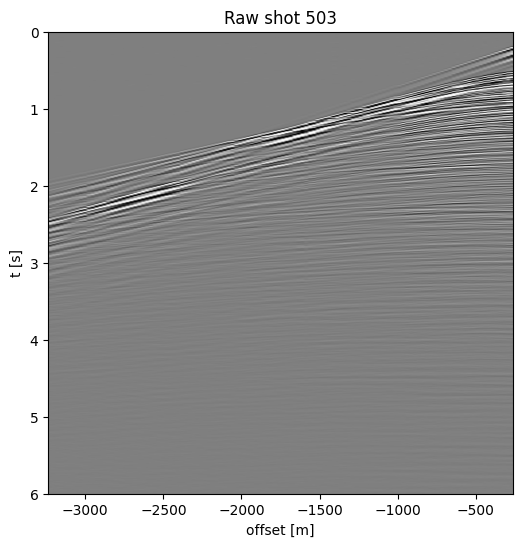

In [2]:
# 1. Load the SEG-Y and check the geometry
H = segyio.TraceField
with segyio.open(SEGY, ignore_geometry=True) as f:
    dt = (f.samples[1] - f.samples[0]) / 1000.0          # [s]
    data = f.trace.raw[:].astype(np.float32)              # [ntraces, nsamples]
    ffid = f.attributes(H.FieldRecord)[:]
    off  = f.attributes(H.offset)[:].astype(float)
    sx   = f.attributes(H.SourceX)[:].astype(float)
    gx   = f.attributes(H.GroupX)[:].astype(float)
    scal = f.attributes(H.SourceGroupScalar)[:]
s = scal[0]
fac = 1.0 if s == 0 else (abs(s) if s > 0 else 1.0 / abs(s))
sx, gx = sx * fac, gx * fac
if np.all(gx == 0):                    # receiver x not filled in: use source x + signed offset
    gx = sx + off
ntr, ns = data.shape
t = np.arange(ns) * dt
assert np.abs(data).max() > 0, "all traces are zero: wrong file?"
print(f"{ntr} traces, {ns} samples, dt = {dt*1e3:.1f} ms, {len(np.unique(ffid))} shots")
print(f"source x {sx.min():.0f}..{sx.max():.0f} m, receiver x {gx.min():.0f}..{gx.max():.0f} m")
print("max |GroupX - SourceX - offset| =", np.abs(gx - sx - off).max(), "m (should be ~0)")

shots_id = np.unique(ffid)
first = {k: i for i, k in reversed(list(enumerate(ffid)))}       # first trace index of each shot
shot_x = np.array([sx[first[k]] for k in shots_id])

def plot_gather(g, title, offs=None, clip=98, ax=None, tmax=None, dt_=None):
    ax = ax or plt.gca()
    c = np.percentile(np.abs(g), clip) + 1e-20
    tend = g.shape[1] * (dt_ or dt)
    ext = [0, g.shape[0], tend, 0] if offs is None else [offs[0], offs[-1], tend, 0]
    ax.imshow(g.T, cmap="gray", aspect="auto", vmin=-c, vmax=c, extent=ext)
    ax.set_title(title); ax.set_ylabel("t [s]"); ax.set_xlabel("offset [m]" if offs is not None else "trace")
    if tmax: ax.set_ylim(tmax, 0)

i0 = np.where(ffid == shots_id[len(shots_id) // 2])[0]
plt.figure(figsize=(6, 6)); plot_gather(data[i0], f"Raw shot {shots_id[len(shots_id)//2]}", off[i0]); plt.show()

killed 4794 bad traces


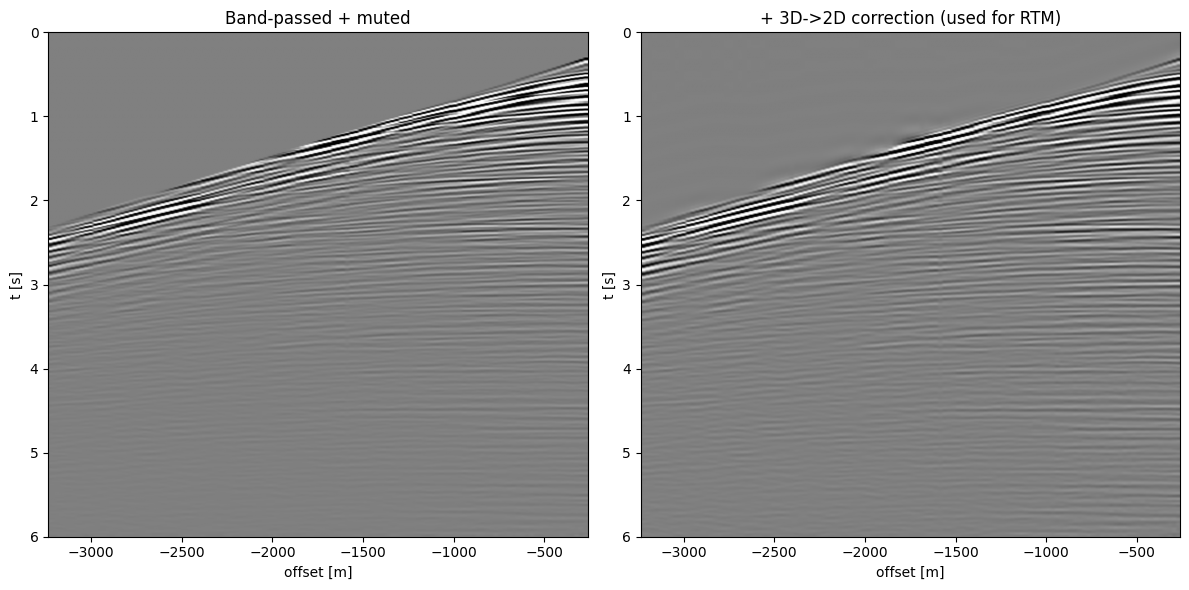

In [3]:
# 2. Pre-processing
# a) bad traces: dead, NaN, or very noisy
rms = np.sqrt(np.mean(data.astype(np.float64) ** 2, axis=1))
bad = (~np.isfinite(rms)) | (rms == 0) | (rms > 5 * np.median(rms[rms > 0]))
data[bad] = 0.0
print(f"killed {bad.sum()} bad traces")

# b) band-pass, c) direct-wave mute, d) 3D->2D correction, all in chunks to limit memory
sos = butter(4, [F_LO, F_HI], btype="band", fs=1.0 / dt, output="sos")
w = 2 * np.pi * np.fft.rfftfreq(ns, dt)
half_int = np.zeros_like(w, dtype=np.complex64)
half_int[1:] = (1j * w[1:]) ** -0.5           # half-integration: 3D point source -> 2D line source
half_int /= np.abs(half_int[np.argmin(np.abs(w / 2 / np.pi - FC))])   # unit gain at FC
sqrt_t = np.sqrt(t).astype(np.float32)

def direct_mute(aoff):
    """Taper (ntr, ns): 0 before the direct wave + 0.1 s, 50 ms cosine ramp."""
    t0 = aoff[:, None] / 1480.0 + 0.10
    r = np.clip((t[None, :] - t0) / 0.05, 0, 1)
    return (0.5 - 0.5 * np.cos(np.pi * r)).astype(np.float32)

proc = np.empty_like(data)       # band-passed + muted (for velocity analysis)
for a in range(0, ntr, 10000):
    b = slice(a, min(a + 10000, ntr))
    x = sosfiltfilt(sos, data[b], axis=1).astype(np.float32)
    proc[b] = x * direct_mute(np.abs(off[b]))
del data                          # free memory; raw data no longer needed

def to_2d(g):
    """3D->2D amplitude/phase correction for one gather: sqrt(t) and half-integration (-45 deg)."""
    G = np.fft.rfft(g, axis=1) * half_int[None, :]
    g2 = np.fft.irfft(G, n=ns, axis=1) * sqrt_t[None, :]
    return sosfiltfilt(sos, g2, axis=1).astype(np.float32)      # remove the boosted low frequencies

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
plot_gather(proc[i0], "Band-passed + muted", off[i0], ax=ax[0])
plot_gather(to_2d(proc[i0]), "+ 3D->2D correction (used for RTM)", off[i0], ax=ax[1])
plt.tight_layout(); plt.show()

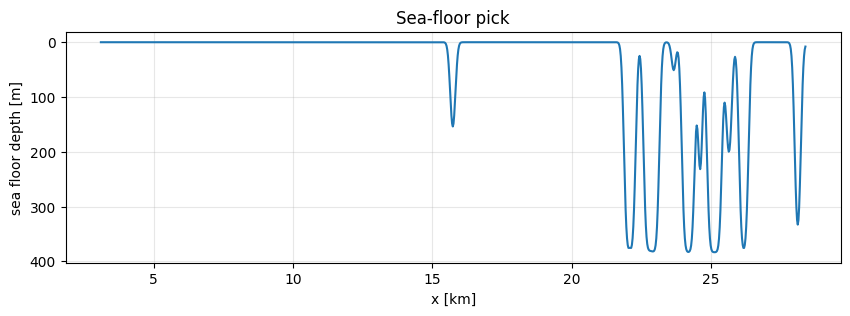

sea floor 0..383 m


In [4]:
# 3. Sea-floor pick (near-offset trace of every shot)
near = np.array([first[k] + np.argmin(np.abs(off[ffid == k])) for k in shots_id])
env = np.abs(hilbert(proc[near], axis=1))
t_wb = np.zeros(len(near))
for j, i in enumerate(near):
    ok = (t > abs(off[i]) / 1480.0 + 0.12) & (t < 2.0)
    e = env[j] * ok
    i1 = np.argmax(e > 0.3 * e.max())                    # first strong onset ...
    i2 = i1 + np.argmax(e[i1:i1 + int(0.15 / dt)])       # ... then its envelope peak
    t_wb[j] = t[i2]
t_wb = median_filter(t_wb, 9)
x_wb = sx[near] + off[near] / 2                         # midpoint of the near trace
z_wb = 0.5 * np.sqrt(np.maximum((V_WATER * t_wb) ** 2 - off[near] ** 2, 0))
z_wb = gaussian_filter1d(z_wb, 3)
t0_wb = 2 * z_wb / V_WATER                              # zero-offset sea-floor time
plt.figure(figsize=(10, 3)); plt.plot(x_wb / 1e3, z_wb); plt.gca().invert_yaxis()
plt.xlabel("x [km]"); plt.ylabel("sea floor depth [m]"); plt.title("Sea-floor pick"); plt.grid(alpha=.3); plt.show()
print(f"sea floor {z_wb.min():.0f}..{z_wb.max():.0f} m")

## Velocity analysis

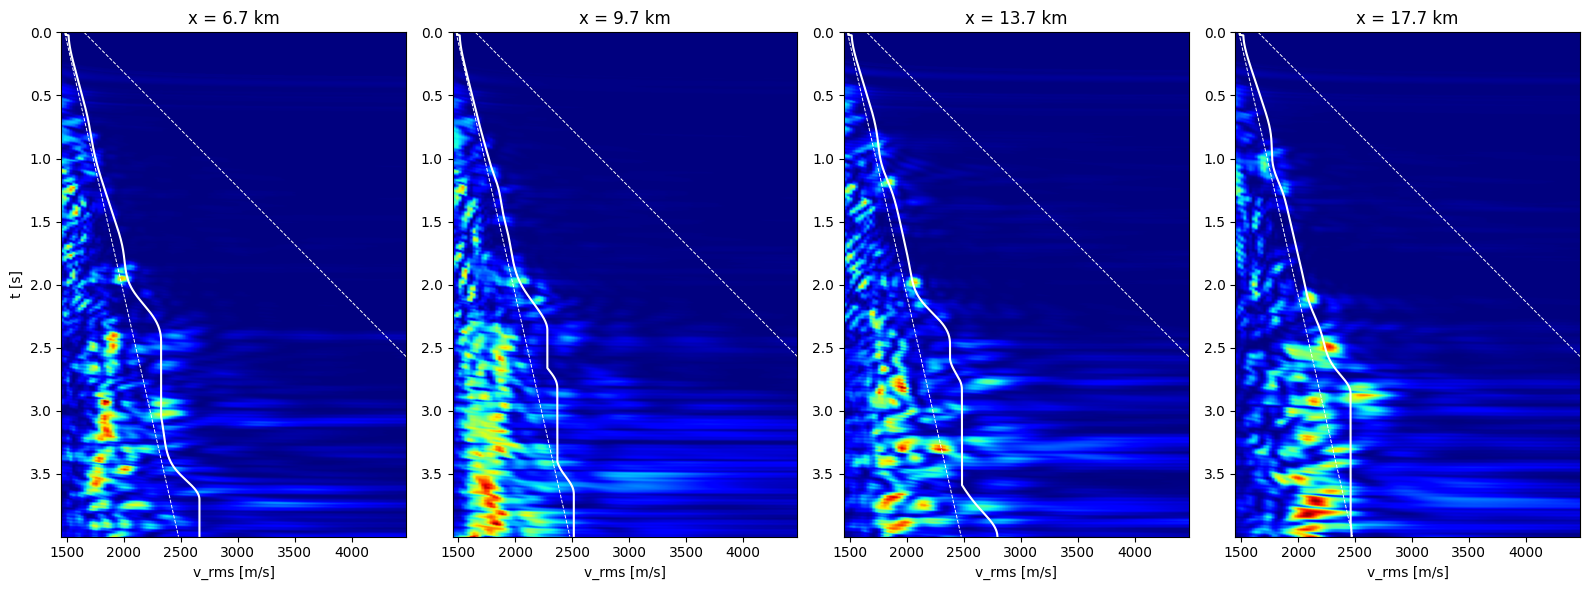

In [7]:
# 4. Velocity analysis
# Semblance on CMP supergathers, picked automatically inside a guide corridor that excludes the
# slow multiples. CHECK THE PANELS: the picks must follow the primaries, not the multiples.
mx, aoff = (sx + gx) / 2, np.abs(off)
vels = np.arange(1450.0, 4500.0, 25.0)
it_max = int(TMAX / dt)
tt = t[:it_max]
SG_HALF = 50.0                    # supergather half-width [m]
V_LOW  = lambda tt: 1480 + 250 * tt          # >>> EDIT guide corridor [m/s] (multiples sit near V_LOW)
V_HIGH = lambda tt: 1650 + 1100 * tt
PICK_THRESH = 0.3                 # pick only times whose semblance peak > 0.3 x the strongest

def semblance(g, h, win=0.04):
    """g [ntr, nt], h offsets -> semblance [nt, nv] with 50 % stretch mute."""
    S = np.zeros((it_max, len(vels)))
    L = max(int(win / dt), 1)
    for k, v in enumerate(vels):
        tn = np.sqrt(tt[None, :] ** 2 + (h[:, None] / v) ** 2)
        idx = tn / dt
        i0_ = np.clip(idx.astype(int), 0, ns - 2); fr = idx - i0_
        m = np.take_along_axis(g, i0_, 1) * (1 - fr) + np.take_along_axis(g, i0_ + 1, 1) * fr
        m[(tn / np.maximum(tt[None, :], dt)) > 1.5] = 0           # stretch mute
        num = uniform_filter1d(m.sum(0) ** 2, L)
        den = uniform_filter1d((m ** 2).sum(0), L) * len(h)
        S[:, k] = num / (den + 1e-30)
    return S

def pick(S, twb0):
    lo, hi = V_LOW(tt), V_HIGH(tt)
    Sm = np.where((vels[None, :] >= lo[:, None]) & (vels[None, :] <= hi[:, None]), S, -1)
    smax = Sm.max(axis=1)
    good = (smax > PICK_THRESH * np.percentile(smax[tt > twb0], 99)) & (tt > twb0)   # times with real events
    vg = vels[np.argmax(Sm, axis=1)].astype(float)
    if good.sum() < 3:
        return np.maximum(V_WATER, V_LOW(tt))
    tg, vg = np.r_[twb0, tt[good]], np.r_[V_WATER, vg[good]]
    v = np.interp(tt, tg, vg)                                   # interpolate between events
    v = gaussian_filter1d(median_filter(v, int(0.3 / dt) | 1), int(0.1 / dt))
    v[tt <= twb0] = V_WATER
    return np.maximum.accumulate(v)            # RMS velocity must not decrease (stable Dix)

x_lo = max(mx.min() + 1700, X_MIN - 3300)     # full fold starts ~half a spread (1.6 km) in
x_hi = min(mx.max() - 1700, X_MAX)
x_va = np.arange(x_lo, x_hi + 1, 1000.0) if x_hi > x_lo else np.array([np.median(mx)])
vrms = []
for xa in x_va:
    sel = np.abs(mx - xa) <= SG_HALF
    S = semblance(proc[sel][:, :ns], aoff[sel])
    vrms.append(pick(S, np.interp(xa, x_wb, t0_wb) + 0.02))
vrms = np.array(vrms)                                       # [n_locations, nt]

nshow = min(4, len(x_va))
fig, ax = plt.subplots(1, nshow, figsize=(4 * nshow, 6), squeeze=False)
for a, j in zip(ax[0], np.linspace(0, len(x_va) - 1, nshow).astype(int)):
    sel = np.abs(mx - x_va[j]) <= SG_HALF
    S = semblance(proc[sel], aoff[sel])
    a.imshow(S, aspect="auto", cmap="jet", extent=[vels[0], vels[-1], tt[-1], 0])
    a.plot(vrms[j], tt, "w", lw=1.5, label="pick")
    a.plot(V_LOW(tt), tt, "w--", lw=.7); a.plot(V_HIGH(tt), tt, "w--", lw=.7)
    a.set_xlim(vels[0], vels[-1]); a.set_ylim(tt[-1], 0)
    a.set_title(f"x = {x_va[j]/1e3:.1f} km"); a.set_xlabel("v_rms [m/s]")
ax[0, 0].set_ylabel("t [s]"); plt.tight_layout(); plt.show()

# Dix -> interval velocity in time -> depth
def dix_depth(vr, zgrid):
    v2t = vr ** 2 * tt
    vint = np.sqrt(np.clip(np.diff(v2t) / np.diff(tt), 1480 ** 2, 5000 ** 2))
    vint = np.concatenate([[vint[0]], vint])
    zt = np.cumsum(vint * dt / 2)                          # depth of each time sample
    return np.interp(zgrid, zt, vint)

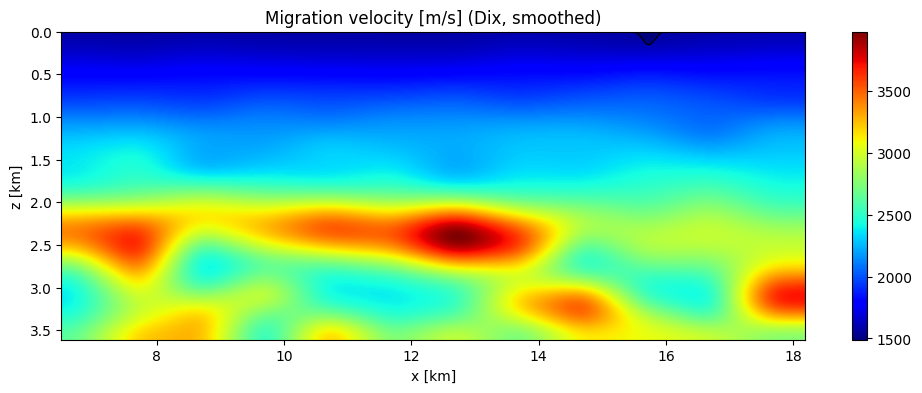

grid 290 x 936 (0.27 M cells), x 6500..18188 m


In [6]:
# 5. Depth velocity model on the DENISE grid
FW = 10
pad = (FW + 6) * DX
x0 = X_MIN - 3300 - pad                     # model origin in data coordinates
nx = int(np.ceil((X_MAX + pad - x0) / DX)); nx += (-nx) % NPROCX
nz = int(np.ceil(ZMAX / DX)) + FW;           nz += (-nz) % NPROCY
xg = x0 + np.arange(nx) * DX                # data x of each grid column
zg = np.arange(nz) * DX
vcols = np.array([dix_depth(v, zg) for v in vrms])         # [n_locations, nz]
vel = np.array([np.interp(xg, x_va, vcols[:, k]) for k in range(nz)])   # [nz, nx]
zwb_g = np.interp(xg, x_wb, z_wb)
water = zg[:, None] < zwb_g[None, :]
vel = gaussian_filter(np.where(water, V_WATER, vel), sigma=200 / DX)
vel = np.where(water, V_WATER, np.clip(vel, 1480, 5000)).astype(np.float32)
rho = np.where(water, 1000.0, 2000.0).astype(np.float32)   # smooth-enough density, no sharp layers below

def show(a, title, cmap="jet", ax=None, **kw):
    ax = ax or plt.gca()
    im = ax.imshow(a, cmap=cmap, aspect="auto", extent=[xg[0] / 1e3, xg[-1] / 1e3, zg[-1] / 1e3, 0], **kw)
    ax.set_title(title); ax.set_xlabel("x [km]"); ax.set_ylabel("z [km]"); plt.colorbar(im, ax=ax)
plt.figure(figsize=(12, 4)); show(vel, "Migration velocity [m/s] (Dix, smoothed)")
plt.plot(xg / 1e3, zwb_g / 1e3, "k", lw=.8); plt.show()
print(f"grid {nz} x {nx} ({nz*nx/1e6:.2f} M cells), x {xg[0]:.0f}..{xg[-1]:.0f} m")

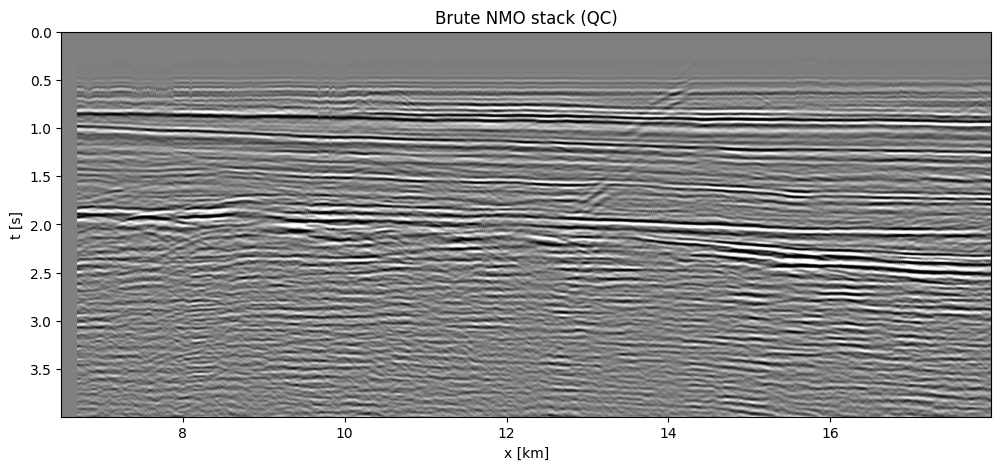

In [8]:
# 6. Brute NMO stack (time) for QC
# A stack shows whether the velocities are reasonable before paying for RTM.
win = (mx >= xg[0] + pad) & (mx <= xg[-1] - pad)
cmp_bin = np.round((mx[win] - xg[0]) / DX).astype(int)
nb = cmp_bin.max() + 1
stack = np.zeros((nb, it_max)); fold = np.zeros((nb, it_max))
vr_bin = np.array([np.interp(xg[0] + np.arange(nb) * DX, x_va, vrms[:, k]) for k in range(it_max)]).T
idx_win = np.where(win)[0]
for a in range(0, len(idx_win), 5000):
    ii = idx_win[a:a + 5000]; bb = cmp_bin[a:a + 5000]
    tn = np.sqrt(tt[None, :] ** 2 + (aoff[ii][:, None] / vr_bin[bb]) ** 2)
    k = np.clip((tn / dt).astype(int), 0, ns - 2); fr = tn / dt - k
    m = np.take_along_axis(proc[ii], k, 1) * (1 - fr) + np.take_along_axis(proc[ii], k + 1, 1) * fr
    ok = (tn / np.maximum(tt[None, :], dt)) <= 1.5
    np.add.at(stack, bb, m * ok); np.add.at(fold, bb, ok)
stack = stack / np.maximum(fold, 1) * tt[None, :] ** 2          # simple t^2 gain for display
c = np.percentile(np.abs(stack), 98)
plt.figure(figsize=(12, 5))
plt.imshow(stack.T, cmap="gray", aspect="auto", vmin=-c, vmax=c,
           extent=[xg[0] / 1e3, (xg[0] + nb * DX) / 1e3, tt[-1], 0])
plt.title("Brute NMO stack (QC)"); plt.xlabel("x [km]"); plt.ylabel("t [s]"); plt.show()

80 shots selected
Init Python 3 API for Denise-Black-Edition.
Check binary in /Users/ahasan/C++/DENISE-Black-Edition/bin/denise
DT = 1.000 ms, NT = 4000
Init Python 3 API for Denise-Black-Edition.
Check binary in /Users/ahasan/C++/DENISE-Black-Edition/bin/denise
/opt/homebrew/bin/mpirun -np 4  /Users/ahasan/C++/DENISE-Black-Edition/bin/denise  /Users/ahasan/vk_rtm/probe/seis.inp /Users/ahasan/vk_rtm/probe/seis_fwi.inp
 *******************************************************************************
 This is program DENISE Black-Edition                                           
 Parallel 2-D elastic Finite Difference FWI code                                
                                                                                
 Forward/FWI/RTM codes written by D. Koehn and D. De Nil                        
 2D isotropic PSV forward code partly based on FDVEPS written by T. Bohlen      
 Institute of Geosciences, Kiel University, Germany                           

 See README.

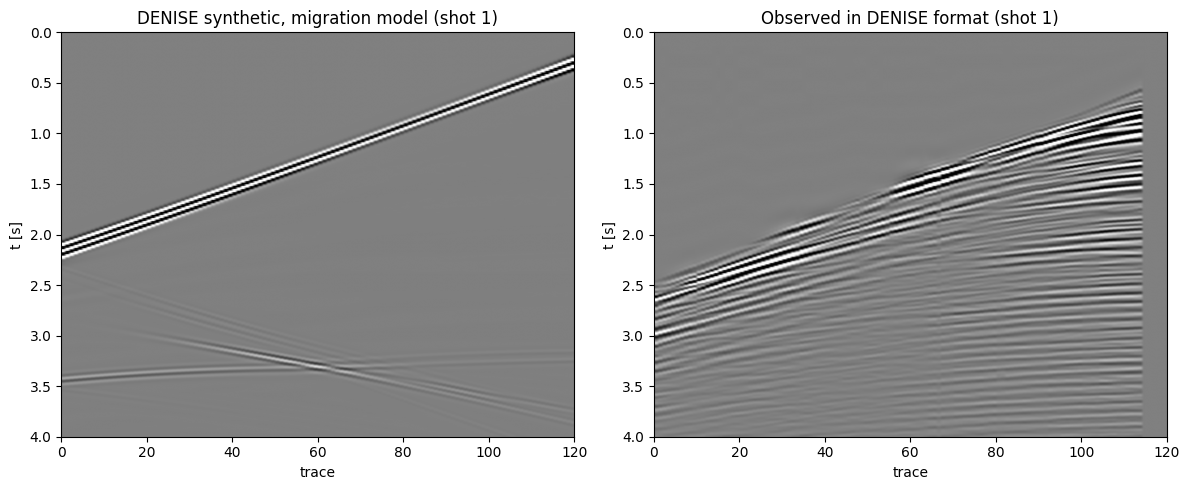

In [9]:
# 7. DENISE set-up and data in DENISE format
sel_shots = shots_id[(shot_x >= X_MIN) & (shot_x <= X_MAX)][::SHOT_STEP]
print(f"{len(sel_shots)} shots selected")

d = api.Denise(DENISE_ROOT, verbose=0)
d.save_folder = os.path.join(WORKDIR, "out/")
if os.path.isdir(d.save_folder):
    shutil.rmtree(d.save_folder)
d.set_paths(makedirs=True)
d.PHYSICS = 2; d.NPROCX, d.NPROCY = NPROCX, NPROCY; d.FD_ORDER = 8
d.QUELLART = 1          # Ricker, peak at t = 1.5 / FC
d.SEISMO = 2; d.QUELLTYPB = 4; d.GRAD_FORM = 2
d.READREC = 2           # one receiver file per shot (moving streamer)
d.N_STREAMER = 0
d.FREE_SURF = 1         # sea surface: the real data contain its ghosts and multiples
d.FW = FW; d.SNAP = 0
d.DH = DX
d.DT = d._check_stability(vel.max() * 1.05, vel.max() * 1.05)
d.NT = int(TMAX / d.DT); d.TIME = d.NT * d.DT; d.NDT = 1
d.DTINV = 2
d.SWS_TAPER_GRAD_HOR = 0
d.TESTSHOT_START, d.TESTSHOT_END, d.TESTSHOT_INCR = 1, len(sel_shots), 1
d.VPUPPERLIM, d.VPLOWERLIM = 5500.0, 1400.0
d.RHOUPPERLIM, d.RHOLOWERLIM = 3000.0, 900.0
print(f"DT = {d.DT*1e3:.3f} ms, NT = {d.NT}")

src = api.Sources(np.array([shot_x[shots_id == k][0] for k in sel_shots]) - x0,
                  SRC_DEPTH * np.ones(len(sel_shots)))
src.fc = FC * np.ones(len(sel_shots))
rec = api.Receivers()
for k in sel_shots:
    ii = np.where(ffid == k)[0]
    rec.add(gx[ii] - x0, REC_DEPTH * np.ones(len(ii)))
assert min(r.x.min() for r in rec.many) > FW * DX, "receivers inside the PML: increase pad"

t_den = (np.arange(d.NT) + 1) * d.DT          # DENISE sample times
t_shift = 1.5 / FC                            # delay of DENISE's Ricker peak

def denise_shot(k):
    """Pre-processed, 2D-corrected gather resampled to DENISE time, shifted by the Ricker delay."""
    ii = np.where(ffid == k)[0]
    g = to_2d(proc[ii])
    cs = CubicSpline(t, g, axis=1, extrapolate=False)
    out = np.nan_to_num(cs(t_den - t_shift)).astype(np.float32)
    return out

def write_su(path, g, dt_s):
    """Minimal little-endian SU writer: 240-byte header (ns, dt) + float32 samples per trace."""
    hdr = np.zeros(240, np.uint8)
    hdr[114:116] = np.frombuffer(np.int16(g.shape[1]).tobytes(), np.uint8)
    hdr[116:118] = np.frombuffer(np.int16(int(round(dt_s * 1e6))).tobytes(), np.uint8)
    with open(path, "wb") as fh:
        for tr in g:
            fh.write(hdr.tobytes()); fh.write(tr.astype("<f4").tobytes())

mig = api.Model(np.flipud(vel), None, np.flipud(rho), DX)

# Amplitude scaling. DENISE's RTM back-propagates residuals (synthetic - observed). Observed data are
# scaled to be ~100x the modelled direct wave, so the residual is effectively the observed data.
probe = api.Denise(DENISE_ROOT, verbose=0)
probe.__dict__.update({k: v for k, v in d.__dict__.items() if k.isupper()})
probe.save_folder = os.path.join(WORKDIR, "probe/")
probe.set_paths(makedirs=True); probe.READREC = 1
psrc = api.Sources(src.x[:1], src.y[:1]); psrc.fc = src.fc[:1]
probe.forward(mig, psrc, api.Receivers(rec.many[0].x, rec.many[0].y), run_command=f"{MPIRUN} -np {NPROCX*NPROCY}")
syn = probe.get_shots(keys="_p")[0]
obs1 = denise_shot(sel_shots[0])
SCALE = 100 * np.abs(syn).max() / (np.abs(obs1).max() + 1e-30)
print(f"data scale factor {SCALE:.3e}")

t1 = time.time()
for j, k in enumerate(sel_shots, start=1):
    write_su(f"{d.DATA_DIR}_p.su.shot{j}", SCALE * denise_shot(k), d.DT)
print(f"wrote {len(sel_shots)} shots in {time.time()-t1:.0f} s")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
plot_gather(syn, "DENISE synthetic, migration model (shot 1)", ax=ax[0], dt_=d.DT)
plot_gather(SCALE * obs1, "Observed in DENISE format (shot 1)", ax=ax[1], dt_=d.DT)
plt.tight_layout(); plt.show()

/opt/homebrew/bin/mpirun -np 4  /Users/ahasan/C++/DENISE-Black-Edition/bin/denise  /Users/ahasan/vk_rtm/out/seis.inp /Users/ahasan/vk_rtm/out/seis_fwi.inp
 *******************************************************************************
 This is program DENISE Black-Edition                                           
 Parallel 2-D elastic Finite Difference FWI code                                
                                                                                
 Forward/FWI/RTM codes written by D. Koehn and D. De Nil                        
 2D isotropic PSV forward code partly based on FDVEPS written by T. Bohlen      
 Institute of Geosciences, Kiel University, Germany                           

 See README.md file and LICENSE.md for redistribution conditions.               
 *******************************************************************************


 **Message from check_model_phys (printed by PE 0):

 -----------------------  DENISE operation mode  -------------

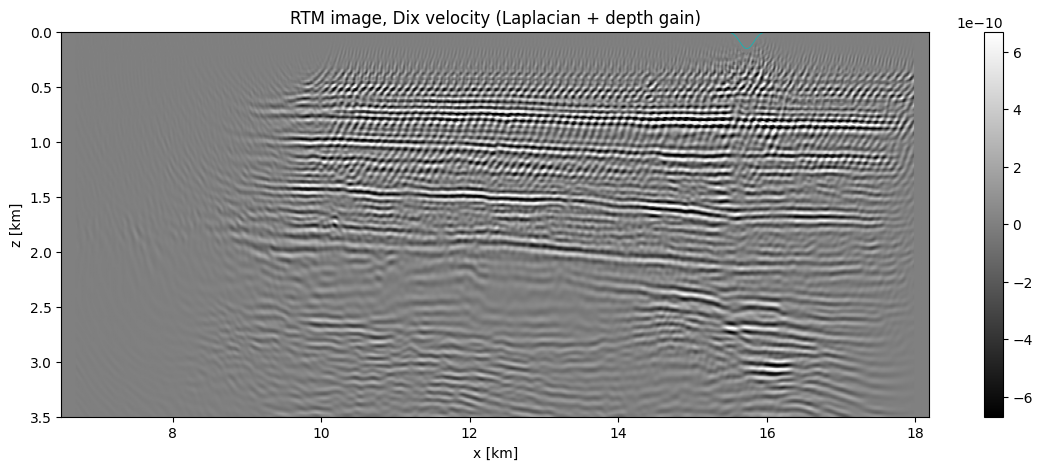

In [10]:
# 8. RTM
def read_bin(path):
    return np.fromfile(path, dtype="<f4").reshape(nx, nz).T

def laplacian(a):
    out = np.zeros_like(a)
    out[1:-1, 1:-1] = a[2:, 1:-1] + a[:-2, 1:-1] + a[1:-1, 2:] + a[1:-1, :-2] - 4 * a[1:-1, 1:-1]
    return out

def rtm(vp_mig, label):
    """Acoustic RTM of the observed data with any velocity model vp_mig [nz, nx]."""
    m = api.Model(np.flipud(vp_mig.astype(np.float32)), None, np.flipud(rho), DX)
    d.MODE = 2; d.RTM_SHOT = 0
    d.fwi_stages = []
    d.add_fwi_stage(time_filt=0, fc_high=F_HI, e_precond=0, lnorm=2)
    d.ITERMAX = 1
    d._write_denise_workflow_header(); d._write_denise_workflow(d.fwi_stages[0])
    t0 = time.time()
    d._engine(m, src, rec, f"{MPIRUN} -np {NPROCX*NPROCY}", False)
    print(f"RTM '{label}': {time.time()-t0:.0f} s")
    raw = read_bin(d.JACOBIAN + "_P_image")
    np.save(os.path.join(WORKDIR, f"rtm_{label}.npy"), raw)
    return raw

def post(raw):
    img = laplacian(raw)
    img[zg[:, None] < zwb_g[None, :] + 3 * DX] = 0          # mute water column
    img *= (zg / zg[-1])[:, None] ** 1.5                    # depth gain (display only)
    img[:, (xg < xg[0] + pad) | (xg > xg[-1] - pad)] = 0
    return img

raw = rtm(vel, "dix")
img = post(raw)
c = np.percentile(np.abs(img), 99)
plt.figure(figsize=(14, 5)); show(img, "RTM image, Dix velocity (Laplacian + depth gain)", cmap="gray", vmin=-c, vmax=c)
plt.plot(xg / 1e3, zwb_g / 1e3, "c", lw=.5); plt.ylim(ZMAX / 1e3, 0); plt.show()
plt.imsave(os.path.join(WORKDIR, "rtm_dix.png"), img, cmap="gray", vmin=-c, vmax=c)

In [11]:
# 9. Velocity sensitivity test (optional, 2 more RTM runs)
# Real-data QC: if the image gets sharper with +-5 % velocity, the Dix model is off in that direction.
RUN_SCAN = False
if RUN_SCAN:
    fig, ax = plt.subplots(3, 1, figsize=(14, 13))
    for a, s_ in zip(ax, [0.95, 1.0, 1.05]):
        v_ = np.where(water, V_WATER, vel * s_).astype(np.float32)
        im_ = post(raw if s_ == 1.0 else rtm(v_, f"x{s_}"))
        show(im_, f"RTM, velocity x {s_}", cmap="gray", ax=a, vmin=-c, vmax=c)
    plt.tight_layout(); plt.show()